In [1]:
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt; plt.rc('font', size=12)
import matplotlib.cm as cm
import seaborn as sns
from scipy.stats import percentileofscore
from scipy.spatial import procrustes
from scipy.spatial.distance import correlation, jensenshannon

In [2]:
taxa = ['B_caccae',
        'B_cellulosilyticus_WH2',
        'B_ovatus',
        'B_thetaiotaomicron',
        'B_uniformis',
        'B_vulgatus',
        'C_aerofaciens',
        'C_scindens',
        'C_spiroforme',
        # 'D_longicatena',
        'P_distasonis',
        'R_obeum'
        ]

pretty_names_dir = {'B_caccae': '$B. caccae$',
                'B_cellulosilyticus_WH2': '$B. cellulosilyticus$',
                'B_ovatus': '$B. ovatus$',
                'B_thetaiotaomicron': '$B. thetaiotaomicron$',
                'B_uniformis': '$B. uniformis$',
                'B_vulgatus': '$B. vulgatus$',
                'C_aerofaciens': '$C. aerofaciens$',
                'C_scindens': '$C. scindens$',
                'C_spiroforme': '$C. spiroforme$',
                # 'D_longicatena': '$D. longicatena$',
                'P_distasonis': '$P. distasonis$',
                'R_obeum': '$R. obeum$'
                }

abbr_names_dir = {'B_caccae': 'Bca',
                'B_cellulosilyticus_WH2': 'Bce',
                'B_ovatus': 'Bov',
                'B_thetaiotaomicron': 'Bth',
                'B_uniformis': 'Bun',
                'B_vulgatus': 'Bvu',
                'C_aerofaciens': 'Cae',
                'C_scindens': 'Csc',
                'C_spiroforme': 'Csp',
                # 'D_longicatena': 'Dlo',
                'P_distasonis': 'Pdi',
                'R_obeum': 'Rob'
                }

pretty_names = [pretty_names_dir[taxa] for taxa in taxa]

order_hm = ['Bce', 'Bov', 'Bth', 'Bvu', 'Bun', 'Bca', 'Pdi', 'Csc', 'Rob', 'Csp', 'Cae']

In [3]:
# Ecological matrix LF0
keystoness_eco_lf0 = pd.read_table('mcnulty-results/best-chains/mcnulty-LF0-seed53/keystoneness.tsv', index_col=0)
# keystoness_eco_lf0.drop(['$C_{1}$', '$C_{2}$', '$C_{3}$'], axis=0, inplace=True)
# keystoness_eco_lf0[keystoness_eco_lf0 > 1] = np.nan
# keystoness_eco_lf0_matrix = np.nan_to_num(keystoness_eco_lf0.values)
# keystoness_eco_lf0 = keystoness_eco_lf0.values.flatten()[~np.isnan(keystoness_eco_lf0.values.flatten())]

# Ecological matrix LF0
keystoness_eco_hf0 = pd.read_table('mcnulty-results/best-chains/mcnulty-HF0-seed3/keystoneness.tsv', index_col=0)
# keystoness_eco_hf0.drop(['$C_{1}$', '$C_{2}$', '$C_{3}$'], axis=0, inplace=True)
# keystoness_eco_hf0[keystoness_eco_hf0 > 1] = np.nan
# keystoness_eco_hf0_matrix = np.nan_to_num(keystoness_eco_hf0.values)
# keystoness_eco_hf0 = keystoness_eco_hf0.values.flatten()[~np.isnan(keystoness_eco_hf0.values.flatten())]

In [4]:
keystoness_eco_lf0

,Bca,Bce,Bov,Bth,Bun,Bvu,Cae,Csc,Csp,Pdi,Rob
Excluded,,,,,,,,,,,
Bca,3.746746,0.001855,0.003814,0.000372,0.001570,0.001251,-0.007132,0.000785,-0.004748,-0.001165,0.000140
Bce,-0.002267,4.322278,0.005116,0.000458,0.000368,0.006767,-0.005042,-0.001017,-0.001572,0.021983,0.000194
Bov,-0.123983,-0.256869,3.701243,-0.004535,-0.006543,-0.009547,0.005229,-0.030931,-0.002027,-0.014234,-0.007633
Bth,-0.018530,-0.108513,-0.004531,3.681788,-0.002596,-0.007044,-0.002749,0.000543,-0.015124,-0.013254,-0.001971
Bun,-0.002623,0.037585,0.016759,0.000720,3.347025,0.007872,-0.023996,0.000988,-0.008082,0.004462,0.000467
Bvu,-0.002549,-0.001026,0.005180,0.000336,0.000764,3.881012,-0.006803,-0.000207,-0.000009,0.001145,0.000161
Cae,-0.018754,-0.072831,-0.017032,-0.006378,-0.011697,-0.012339,2.346886,-0.010496,-0.013104,-0.012109,-0.005492
Csc,0.001211,-0.001166,-0.000106,0.000701,0.001594,0.000165,-0.004083,2.783284,-0.001975,-0.000506,-0.000205
Csp,-0.040654,-0.033851,-0.006235,-0.004970,-0.005200,-0.014269,-0.001172,-0.007242,1.729965,-0.003652,-0.002687


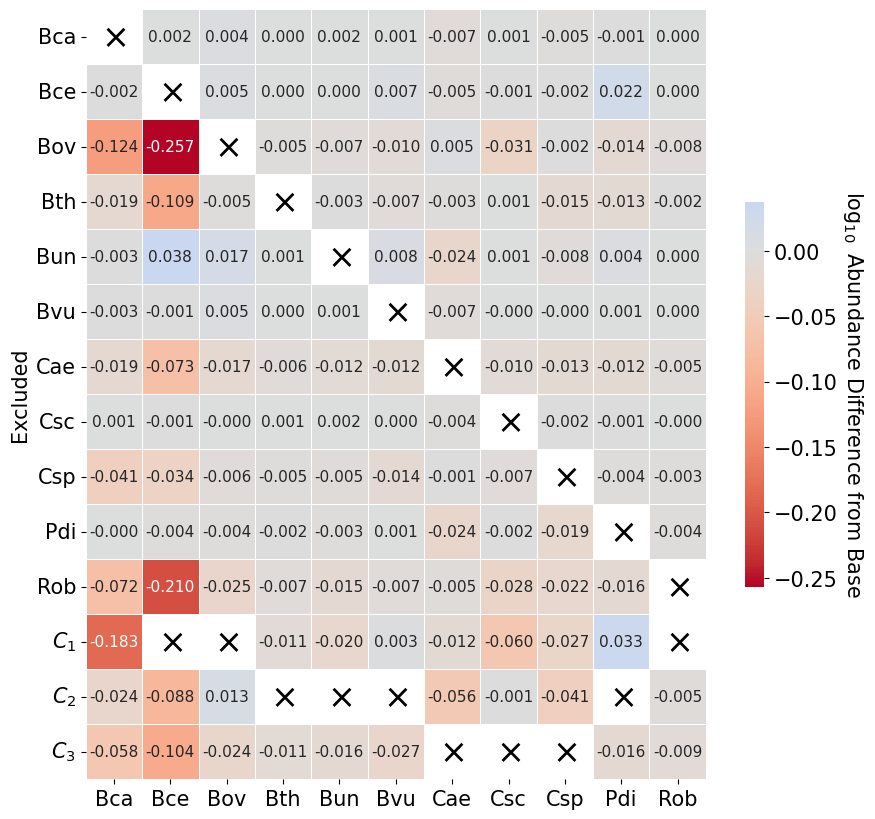

In [5]:
mask = keystoness_eco_lf0 > 1
plt.rc('font', size=15)
cmap = sns.color_palette("coolwarm_r", as_cmap=True)
plt.figure(figsize=(10,10))
ax = sns.heatmap(keystoness_eco_lf0, 
    cmap=cmap, 
    mask=mask, 
    center=0, 
    # square=True, 
    cbar_kws={"shrink": .5}, 
    linewidths=0.5,
    linecolor='w',
    annot=True,
    fmt='.3f',
    annot_kws={'size': 11}
    )
for i in range(mask.shape[0]):
    for j in range(mask.shape[1]):
        if mask.iloc[i,j] == True:
            plt.text(j+0.5, i+0.5, '$\\times$', ha='center', va='center', color='k', fontsize=24)
cbar = ax.collections[0].colorbar
cbar.set_label('$\log_{10}$ Abundance Difference from Base', rotation=270, fontsize=15, labelpad=20)
ax.set_xticklabels(ax.get_xticklabels(), ha='center')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right')
# ax.set_yticks([])
# ax.set_xticklabels([], ha='right')
# plt.savefig('mcnulty-results/best-chains/mcnulty-LF0-seed53/keystoneness/keystoneness.svg', bbox_inches='tight')
plt.show()

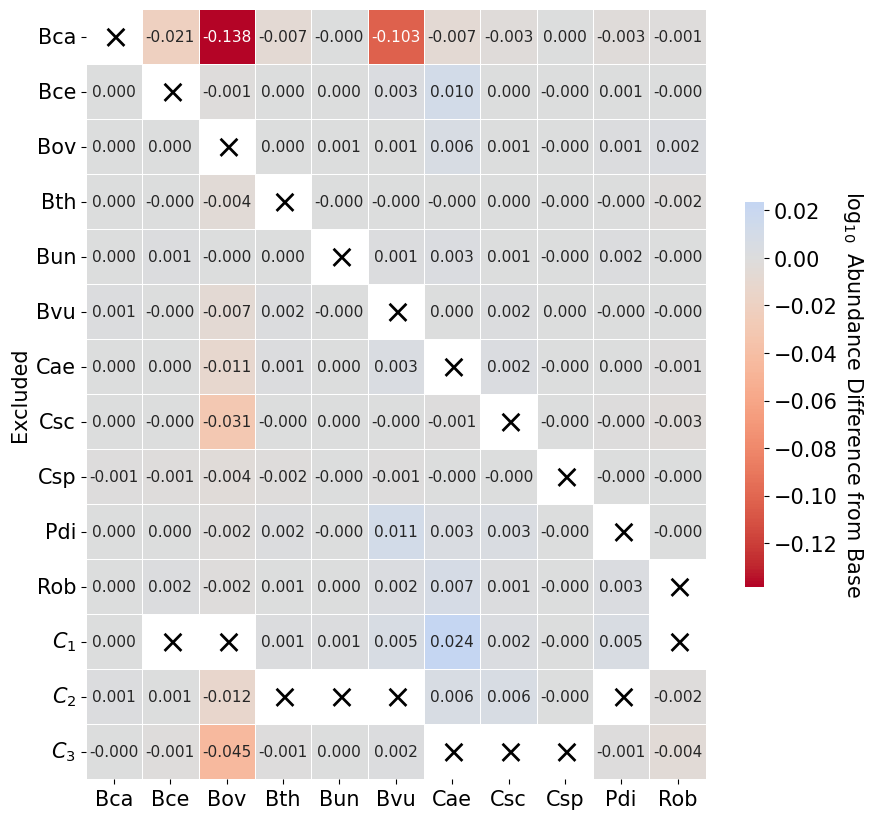

In [9]:
from matplotlib.colors import LogNorm

mask = keystoness_eco_hf0 > 1
plt.rc('font', size=15)
cmap = sns.color_palette("coolwarm_r", as_cmap=True)
plt.figure(figsize=(10,10))
ax = sns.heatmap(keystoness_eco_hf0, 
    cmap=cmap, 
    mask=mask, 
    center=0, 
    # square=True, 
    cbar_kws={"shrink": .5}, 
    linewidths=0.5,
    linecolor='w',
    annot=True,
    fmt='.3f',
    annot_kws={'size': 11},
    # norm=LogNorm()
    )
for i in range(mask.shape[0]):
    for j in range(mask.shape[1]):
        if mask.iloc[i,j] == True:
            plt.text(j+0.5, i+0.5, '$\\times$', ha='center', va='center', color='k', fontsize=24)
cbar = ax.collections[0].colorbar
cbar.set_label('$\log_{10}$ Abundance Difference from Base', rotation=270, fontsize=15, labelpad=20)
ax.set_xticklabels(ax.get_xticklabels(), ha='center')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right')
# plt.savefig('mcnulty-results/mcnulty-HF0-seed3/keystoneness-individual/keystoneness.svg', bbox_inches='tight')
plt.show()

In [12]:
np.log10(0.01)

-2.0

In [13]:
np.log10(0.0001)

-4.0

In [16]:
1e-8/(1e-8)

1.0

In [ ]:
# https://kar.kent.ac.uk/32810/2/2012_Bi-symmetric-log-transformation_v5.pdf

In [34]:
def bi_symmetric_log_transformation(x):
    C = np.min(np.abs(x))*1000
    return np.sign(x) * np.log10(1 + np.abs(x/C))

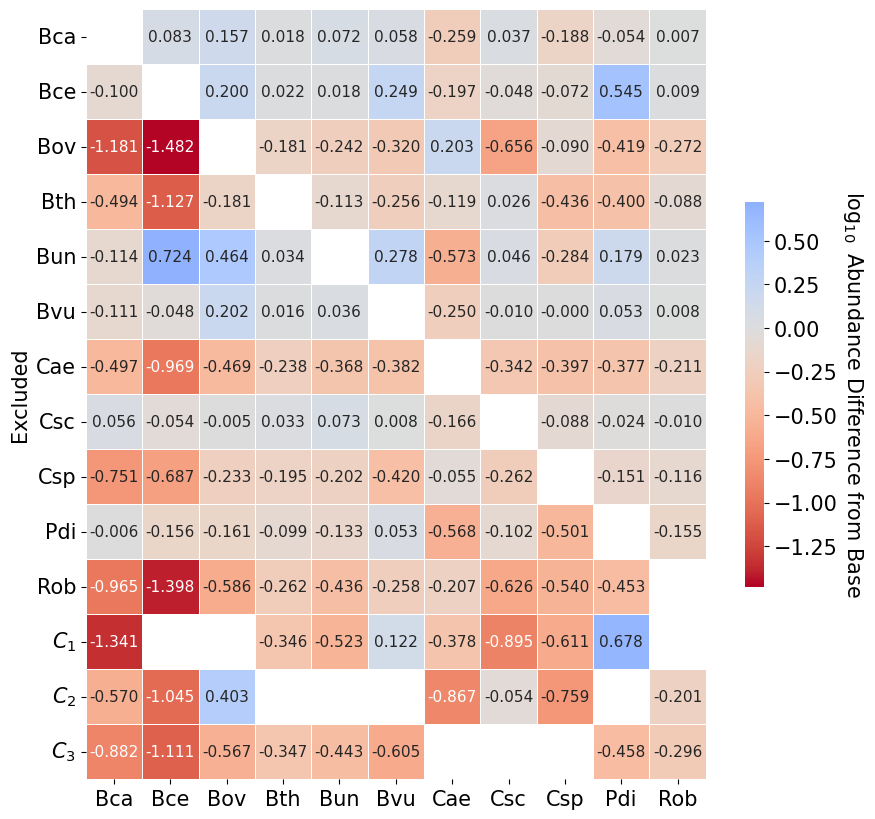

In [35]:
x = bi_symmetric_log_transformation(keystoness_eco_lf0)
# mask = x > 1
plt.rc('font', size=15)
cmap = sns.color_palette("coolwarm_r", as_cmap=True)
plt.figure(figsize=(10,10))
ax = sns.heatmap(x, 
    cmap=cmap, 
    mask=mask, 
    center=0, 
    # square=True, 
    cbar_kws={"shrink": .5}, 
    linewidths=0.5,
    linecolor='w',
    annot=True,
    fmt='.3f',
    annot_kws={'size': 11}
    )
# for i in range(mask.shape[0]):
#     for j in range(mask.shape[1]):
#         if mask.iloc[i,j] == True:
#             plt.text(j+0.5, i+0.5, '$\\times$', ha='center', va='center', color='k', fontsize=24)
cbar = ax.collections[0].colorbar
cbar.set_label('$\log_{10}$ Abundance Difference from Base', rotation=270, fontsize=15, labelpad=20)
ax.set_xticklabels(ax.get_xticklabels(), ha='center')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0, ha='right')
# ax.set_yticks([])
# ax.set_xticklabels([], ha='right')
# plt.savefig('mcnulty-results/best-chains/mcnulty-LF0-seed53/keystoneness/keystoneness.svg', bbox_inches='tight')
plt.show()

In [25]:
keystoness_eco_lf0

,Bca,Bce,Bov,Bth,Bun,Bvu,Cae,Csc,Csp,Pdi,Rob
Excluded,,,,,,,,,,,
Bca,3.746746,0.001855,0.003814,0.000372,0.001570,0.001251,-0.007132,0.000785,-0.004748,-0.001165,0.000140
Bce,-0.002267,4.322278,0.005116,0.000458,0.000368,0.006767,-0.005042,-0.001017,-0.001572,0.021983,0.000194
Bov,-0.123983,-0.256869,3.701243,-0.004535,-0.006543,-0.009547,0.005229,-0.030931,-0.002027,-0.014234,-0.007633
Bth,-0.018530,-0.108513,-0.004531,3.681788,-0.002596,-0.007044,-0.002749,0.000543,-0.015124,-0.013254,-0.001971
Bun,-0.002623,0.037585,0.016759,0.000720,3.347025,0.007872,-0.023996,0.000988,-0.008082,0.004462,0.000467
Bvu,-0.002549,-0.001026,0.005180,0.000336,0.000764,3.881012,-0.006803,-0.000207,-0.000009,0.001145,0.000161
Cae,-0.018754,-0.072831,-0.017032,-0.006378,-0.011697,-0.012339,2.346886,-0.010496,-0.013104,-0.012109,-0.005492
Csc,0.001211,-0.001166,-0.000106,0.000701,0.001594,0.000165,-0.004083,2.783284,-0.001975,-0.000506,-0.000205
Csp,-0.040654,-0.033851,-0.006235,-0.004970,-0.005200,-0.014269,-0.001172,-0.007242,1.729965,-0.003652,-0.002687
